<a href="https://colab.research.google.com/github/janpeter19/BPL_TEST2_Chemostat/blob/main/BPL_TEST2_Chemostat_oms_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# BPL_TEST2_Chemostat script with OMSimulator

The key library OMSimulator is installed.

After the installation a small application BPL_TEST2_Chemostat is loaded and run. You can continue with this example if you like.

In [1]:
!lsb_release -a # Actual VM Ubuntu version used by Google

No LSB modules are available.
Distributor ID:	Ubuntu
Description:	Ubuntu 24.04.5 LTS
Release:	24.04
Codename:	noble


In [2]:
!python --version

Python 3.13.18


In [3]:
%pip install -q uv

In [4]:
!uv pip install OMSimulator # Install the key package

Using Python 3.13.18 environment at: /usr
Resolved 7 packages in 204ms
Prepared 1 package in 4.86s
Installed 1 package in 4ms
 + omsimulator==3.0.0.post198


In [5]:
!uv pip install --system git+https://github.com/janpeter19/FMU_explore.git@v1.2.6

Using Python 3.13.18 environment at: /usr
Resolved 1 package in 341ms
Prepared 1 package in 3.03s
Installed 1 package in 1ms
 + fmu-explore==1.2.6 (from git+https://github.com/janpeter19/FMU_explore.git@573ae8b5a2daf5d983a5cf2d98abbd78ab7da18e)


In [6]:
!uv pip install DyMat

Using Python 3.13.18 environment at: /usr
Resolved 1 package in 870ms
Prepared 1 package in 343ms
Installed 1 package in 1ms
 + dymat==0.7


## Now specific installation run a simulation and notebook for that

Start with connecting to Github. Then upload the two files:

* FMU - BPL_TEST2_Chemostat_linux_om_me.fmu
* Setup-file - BPL_TEST2_Chemostat_oms.py
* Setup-file - BPL_TEST2_Chemostat_oms_explore.py

In [7]:
%%bash
git clone https://github.com/janpeter19/BPL_TEST2_Chemostat

Cloning into 'BPL_TEST2_Chemostat'...


In [8]:
%cd BPL_TEST2_Chemostat

/content/BPL_TEST2_Chemostat


## BPL_TEST2_Chemostat - demo

In [9]:
# Import the application model and context variables
from BPL_TEST2_Chemostat_oms import*

Linux - run FMU pre-compiled OpenModelica


In [10]:
# Import the general FMU_explore functions and adapt them to the application
from fmu_explore_oms import AdaptWith

Application = AdaptWith(parValue, parLocation, parCheck, \
                        fmu_model, fmu_process_diagram, \
                        MSL_usage, MSL_version, BPL_version, \
                        options, simulationTime, timeDiscreteStates, \
                        diagrams, ax, lines)

par = Application.par
init = Application.init
#disp = Application.disp
simu = Application.simu
show = Application.show

resetPen = Application.resetPen
process_diagram = Application.process_diagram
#describe_general = Application.describe_general
#describe_parts = Application.describe_parts
describe_MSL = Application.describe_MSL
#cstrProdMax = Application.external_function

FMU_explore_info = Application.FMU_explore_info
system_info = Application.system_info
SDG = Application.SDG

In [11]:
run -i BPL_TEST2_Chemostat_oms_explore.py


Model for the process has been setup. Key commands:
 - par()       - change of parameters and initial values
 - init()      - change initial values only
 - simu()      - simulate and plot
 - newplot()   - make a new plot
 - show()      - show plot from previous simulation
 - disp()      - display parameters and initial values from the last simulation
 - describe()  - describe culture, broth, parameters, variables with values/units

Note that both disp() and describe() takes values from the last simulation
and the command process_diagram() brings up the main configuration

Brief information about a command by help(), eg help(simu)
Key system information is listed with the command system_info()


In [12]:
%matplotlib inline
plt.rcParams['figure.figsize'] = [25/2.54, 20/2.54]

In [13]:
#describe('process')

In [14]:
describe('culture')

Simplified text book model - only substrate S and cell concentration X


No processDiagram.png file in the FMU, but try the file on disk.


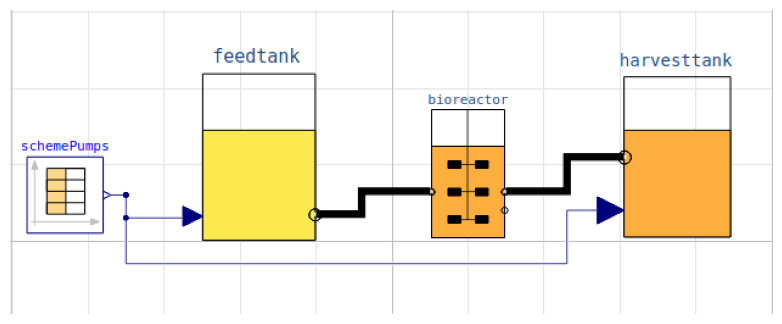

In [15]:
process_diagram()

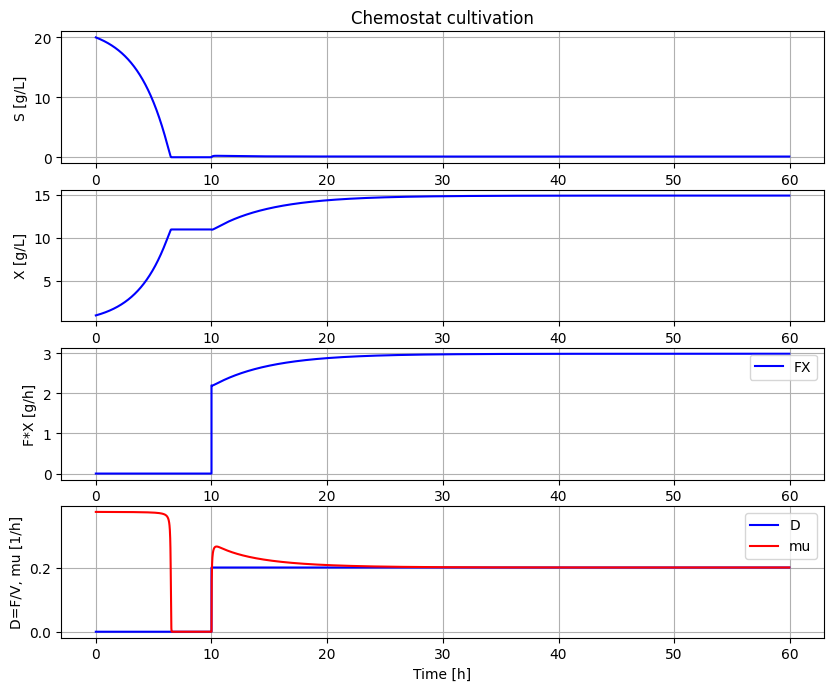

In [16]:
newplot()
par(Y=0.50, qSmax=0.75,  Ks=0.1)               # Culture parameters
init(V_start=1.0, VX_start=1.0, VS_start=20)   # Bioreactor startup
par(S_in=30, t0=0, F0=0, t1=10, F1=0.2)        # Substrate feeding
simu(60)

RuntimeError: Failed to create new model: Status.error

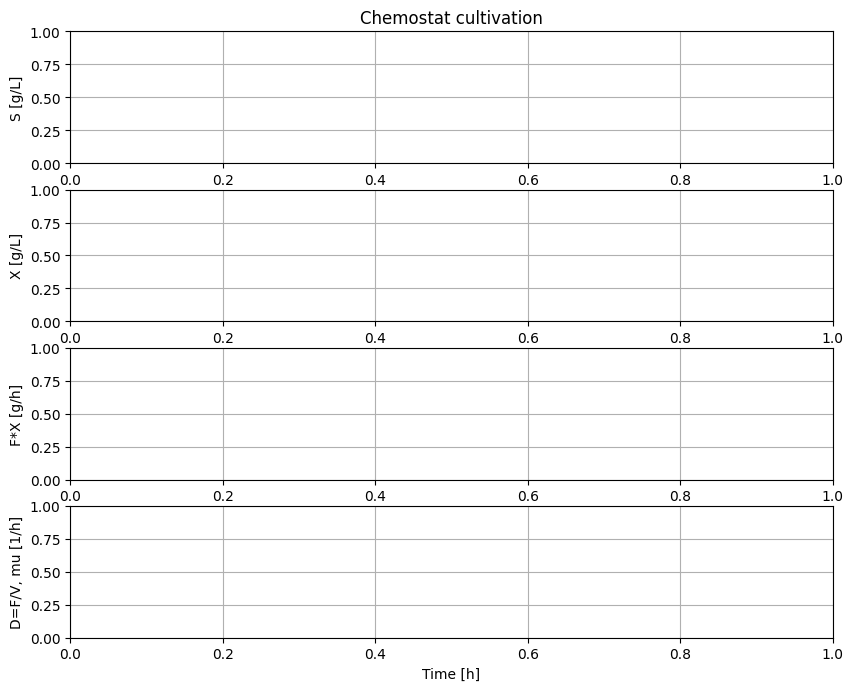

In [18]:
# Test simu('cont')
newplot()
simu(20)
#simu(40,'cont')

In [ ]:
#describe('parts')

In [ ]:
describe('MSL')

In [ ]:
system_info()

In [ ]:
!lsb_release -d

In [ ]:
SDG()